# 04 · Decision policy and interpretability

Everything here uses the current production champion (`artifacts/champion`, written by `churn simulate`) evaluated on the frozen holdout,
so it describes the model that is actually deployed.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn import config

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

import shap
from sklearn.metrics import confusion_matrix, roc_auc_score

from churn.data.ingest import X_y, load_split
from churn.decision.policy import customer_value, decide, expected_value, net_value
from churn.models.bundle import load_bundle
from churn.models.evaluate import segment_report
from churn.models.interpret import base_pipeline

bundle = load_bundle(config.CHAMPION_DIR)
model, policy, meta = bundle["model"], bundle["policy"], bundle["metadata"]
holdout = load_split("holdout")
X, y = X_y(holdout)
proba = model.predict_proba(X)[:, 1]
value = customer_value(X)
contact = decide(proba, value, policy)
print(f"champion v{meta['version']} ({meta['model']}), rule: {policy['rule']}")

champion v1 (gradient_boosting), rule: expected_value


## 1. Value of the campaign by decision rule

expected value rule      62715.0
best threshold (0.21)    61239.0
threshold 0.5            48217.0
dtype: float64

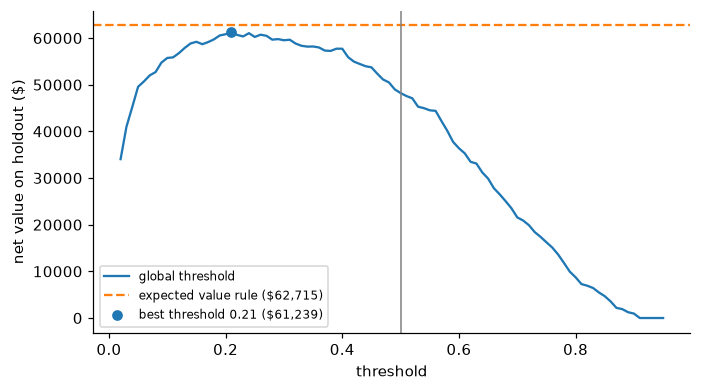

In [2]:
grid = np.round(np.arange(0.02, 0.96, 0.01), 2)
by_threshold = [net_value(y, proba >= t, value) for t in grid]
ev_value = net_value(y, contact, value)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, by_threshold, label="global threshold")
ax.axhline(ev_value, color="C1", ls="--", label=f"expected value rule (${ev_value:,.0f})")
ax.axvline(0.5, color="grey", lw=1)
best = int(np.argmax(by_threshold))
ax.scatter(grid[best], by_threshold[best], color="C0", zorder=3, label=f"best threshold {grid[best]} (${by_threshold[best]:,.0f})")
ax.set_xlabel("threshold")
ax.set_ylabel("net value on holdout ($)")
ax.legend(fontsize=8)
pd.Series({"expected value rule": ev_value, f"best threshold ({grid[best]})": by_threshold[best], "threshold 0.5": net_value(y, proba >= 0.5, value)}).round(0)

On the holdout, the champion's **expected-value rule earns $62.7k**, against $61.2k for the best possible global threshold (0.21) and $48.2k at the default 0.5.
Using 0.5 would leave 23% of the value on the table. The expected-value rule beats even the best threshold because it uses information a single
cut-off can't: two customers with the same probability are worth contacting or not depending on their bill.

## 2. Where the money comes from

In [3]:
tn, fp, fn, tp = confusion_matrix(y, contact).ravel()
saved = config.OFFER_SUCCESS_RATE * value[(y == 1) & contact]
breakdown = pd.Series({
    "contacted churners (TP)": tp,
    "contacted non-churners (FP)": fp,
    "missed churners (FN)": fn,
    "left alone, stayed (TN)": tn,
    "expected revenue saved from TP ($)": saved.sum(),
    "offer cost on all contacts ($)": config.RETENTION_OFFER_COST * contact.sum(),
    "net value ($)": net_value(y, contact, value),
    "revenue of missed churners ($)": value[(y == 1) & ~contact].sum(),
})
breakdown.round(0)

contacted churners (TP)                  298.0
contacted non-churners (FP)              352.0
missed churners (FN)                      76.0
left alone, stayed (TN)                  683.0
expected revenue saved from TP ($)    101715.0
offer cost on all contacts ($)         39000.0
net value ($)                          62715.0
revenue of missed churners ($)         39025.0
dtype: float64

Of 1,409 holdout customers, 650 (46%) get the offer. 298 of them are real churners and 352 would have stayed anyway, so a bit more than half the offers go to customers
who didn't need them. That's the price of catching 80% of churners, and the economics still work: $101.7k of expected saved revenue against $39.0k in offers.

The 76 missed churners represent $39.0k of revenue. Section 9 shows that most of them were missed on purpose.

## 3. Sensitivity to the business assumptions

Offer cost ($60) and acceptance rate (35%) are assumptions. If they're wrong, how wrong is the campaign?
Each cell re-applies the expected-value rule under different assumptions.

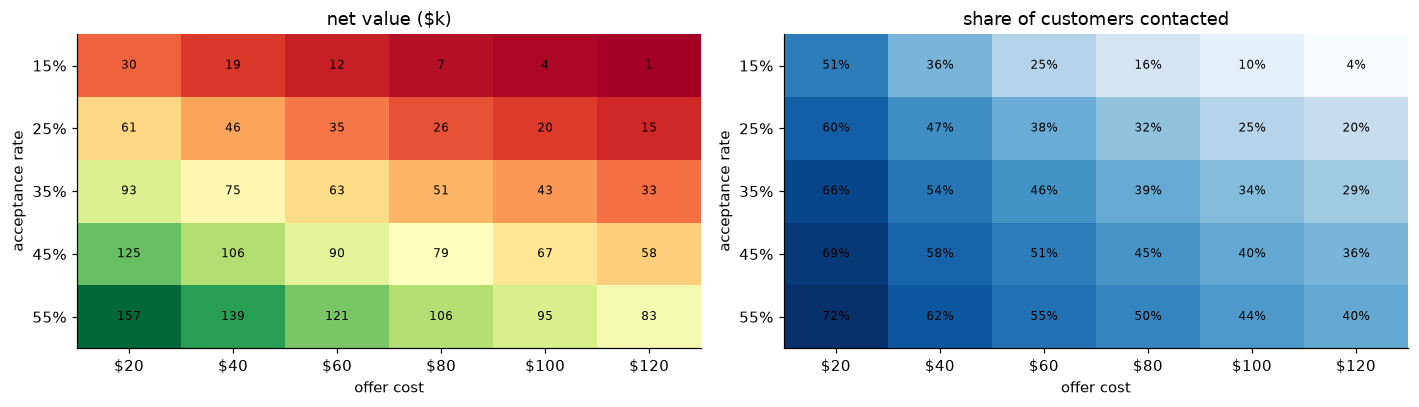

In [4]:
costs = [20, 40, 60, 80, 100, 120]
rates = [0.15, 0.25, 0.35, 0.45, 0.55]
value_grid = pd.DataFrame(index=rates, columns=costs, dtype=float)
contact_grid = value_grid.copy()
for rate in rates:
    for cost in costs:
        chosen = proba * rate * value > cost
        gain = np.where(y == 1, rate * value - cost, -cost)
        value_grid.loc[rate, cost] = gain[chosen].sum()
        contact_grid.loc[rate, cost] = chosen.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, grid_, title, fmt in [(axes[0], value_grid, "net value ($k)", lambda v: f"{v / 1000:.0f}"), (axes[1], contact_grid, "share of customers contacted", lambda v: f"{v:.0%}")]:
    ax.imshow(grid_.astype(float), cmap="RdYlGn" if "value" in title else "Blues", aspect="auto")
    ax.set_xticks(range(len(costs)), [f"${c}" for c in costs])
    ax.set_yticks(range(len(rates)), [f"{r:.0%}" for r in rates])
    ax.set_xlabel("offer cost")
    ax.set_ylabel("acceptance rate")
    ax.set_title(title)
    for i in range(len(rates)):
        for j in range(len(costs)):
            ax.text(j, i, fmt(grid_.iloc[i, j]), ha="center", va="center", fontsize=8)
fig.tight_layout()

The rule protects itself. Under every combination in the grid **net value stays positive**, because when offers get expensive or acceptance drops,
the rule simply contacts fewer people. At a 15% acceptance rate and a $120 offer it contacts 4% of customers and still makes $1.1k. A fixed threshold would keep contacting
46% and lose money.

The assumptions still matter a lot for the size of the prize: at a $60 offer it ranges from $12k (15% acceptance) to $121k (55%). Estimating the acceptance rate with a
proper control group would be the highest-value next step on the business side.

## 4. The contact list

In [5]:
ranked = holdout.assign(churn_probability=proba, customer_value=value, expected_value=expected_value(proba, value), contact=contact)
ranked = ranked.sort_values("expected_value", ascending=False)
ranked[[config.ID_COL, "contract", "tenure", "monthly_charges", "churn_probability", "customer_value", "expected_value", "contact"]].head(10)

,customer_id,contract,tenure,monthly_charges,churn_probability,customer_value,expected_value,contact
911,5419-JPRRN,Month-to-month,1,101.45,0.889,1217.4,318.804,True
702,9300-AGZNL,Month-to-month,1,94.00,0.903,1128.0,296.584,True
973,0781-LKXBR,Month-to-month,9,100.50,0.845,1206.0,296.468,True
102,6210-KBBPI,Month-to-month,9,99.45,0.853,1193.4,296.393,True
432,4132-KALRO,Month-to-month,4,100.85,0.839,1210.2,295.222,True
819,0722-SVSFK,Month-to-month,7,100.40,0.810,1204.8,281.429,True
1016,2081-VEYEH,Month-to-month,3,107.95,0.749,1295.4,279.640,True
1223,3068-OMWZA,Month-to-month,1,88.80,0.905,1065.6,277.500,True
648,9172-ANCRX,Month-to-month,10,98.70,0.810,1184.4,275.965,True
827,7450-NWRTR,Month-to-month,12,99.45,0.803,1193.4,275.329,True


In [6]:
# High probability doesn't guarantee a contact: a cheap plan can't pay for the offer
cheap_risky = ranked[(ranked["churn_probability"] > 0.5) & ~ranked["contact"]]
print(f"{len(cheap_risky)} customers with p > 0.5 are NOT contacted")
cheap_risky[["contract", "monthly_charges", "churn_probability", "expected_value"]].describe().loc[["count", "mean", "min", "max"]]

5 customers with p > 0.5 are NOT contacted


,monthly_charges,churn_probability,expected_value
count,5.00,5.000,5.000
mean,22.93,0.547,-7.429
min,20.15,0.510,-12.141
max,25.15,0.566,-1.289


The list is ordered by expected value, not probability, so the top of the list is high-risk customers on expensive plans: month-to-month, a few months in, ~$100/month.

The reverse also happens. Five customers with a churn probability above 0.5 are not contacted. All of them pay $20-25/month, and at that price the most we could save
(35% x 12 months x ~$23 ≈ $97, times p ≈ 0.55) doesn't cover a $60 offer. For a $20/month customer the break-even probability is 0.71; for a $100/month customer it's 0.14.

## 5. Global drivers (SHAP)

SHAP values on the base model (log-odds). Platt scaling is monotonic, so the ranking of drivers holds for the calibrated probability.

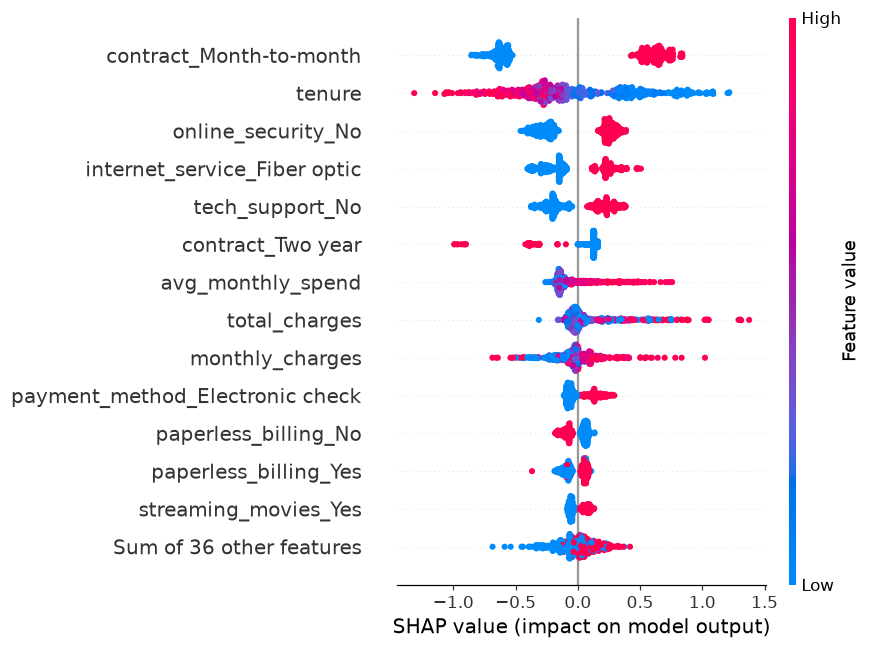

In [7]:
pipe = base_pipeline(model)
features, clf = pipe.named_steps["features"], pipe.named_steps["clf"]
sample = X.sample(600, random_state=config.RANDOM_STATE)
Xt = features.transform(sample)
names = list(features.named_steps["prep"].get_feature_names_out())
explainer = shap.TreeExplainer(clf, feature_perturbation="tree_path_dependent") if hasattr(clf, "estimators_") else shap.LinearExplainer(clf, Xt[:100])
explanation = explainer(Xt)
explanation.feature_names = [n.split("__", 1)[1] for n in names]
if explanation.values.ndim == 3:
    explanation = explanation[:, :, 1]
shap.plots.beeswarm(explanation, max_display=14, show=False)
plt.gcf().set_size_inches(8, 6)
plt.tight_layout()

## 6. How the main drivers act

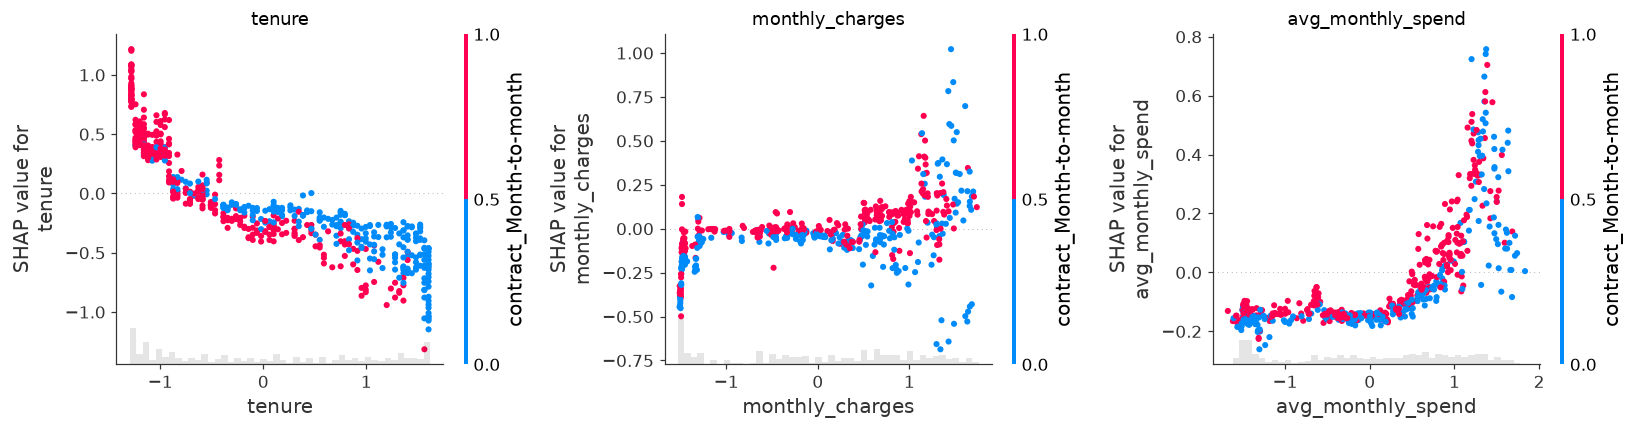

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["tenure", "monthly_charges", "avg_monthly_spend"]):
    shap.plots.scatter(explanation[:, feature], color=explanation[:, "contract_Month-to-month"], ax=ax, show=False)
    ax.set_title(feature)
fig.tight_layout()

- **Tenure:** its contribution falls monotonically across the whole range. Average SHAP goes from +0.62 log-odds in the first six months to -0.24 at 2-4 years and -0.51 after four years.
  It weighs a bit more for month-to-month customers (mean |SHAP| 0.43 vs 0.35), which is the contract x tenure interaction from the EDA.
- **Monthly charges:** a mild, gradual effect, from -0.16 below $30 to +0.10 above $90. Much of the price signal goes through internet type (fiber) instead.
- **avg_monthly_spend:** its average impact (mean |SHAP| 0.15) is larger than that of `monthly_charges` (0.12). The tree model uses it for the price-change signal from notebook 02,
  even though it barely helped the linear model. That's why I keep the feature.

## 7. Two individual explanations

highest risk: p = 0.908 | Month-to-month, tenure 1, $85.45/month, internet Fiber optic


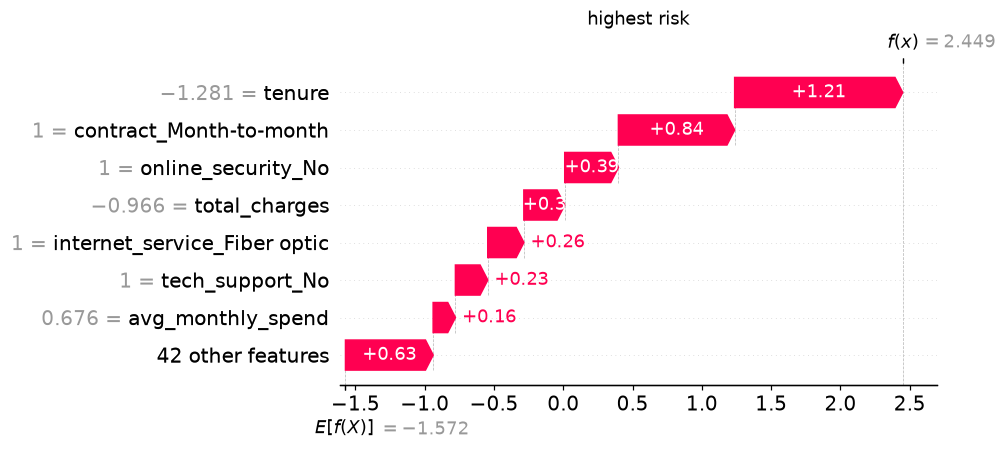

lowest risk: p = 0.014 | Two year, tenure 71, $24.7/month, internet No


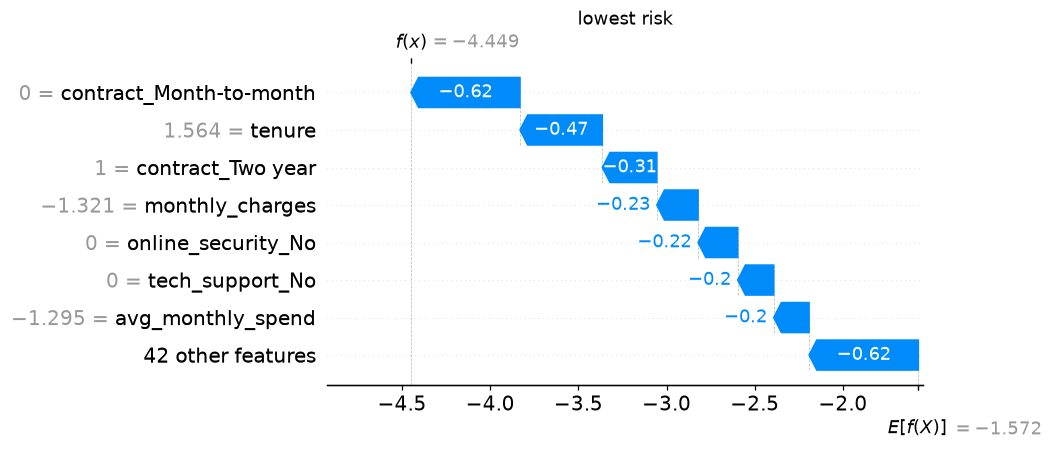

In [9]:
sample_proba = model.predict_proba(sample)[:, 1]
high, low = int(np.argmax(sample_proba)), int(np.argmin(sample_proba))
for idx, label in [(high, "highest risk"), (low, "lowest risk")]:
    row = sample.iloc[idx]
    print(f"{label}: p = {sample_proba[idx]:.3f} | {row['contract']}, tenure {row['tenure']}, ${row['monthly_charges']}/month, internet {row['internet_service']}")
    shap.plots.waterfall(explanation[idx], max_display=8, show=False)
    plt.gcf().set_size_inches(7, 3.8)
    plt.title(label)
    plt.show()

## 8. Performance by driver

In [10]:
segments = segment_report(X, y, proba, contact)
overall = 2 * roc_auc_score(y, proba) - 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = segments["segment"] + ": " + segments["value"].astype(str)
axes[0].barh(labels, segments["gini"], color="#3b6ea5")
axes[0].axvline(overall, color="C3", ls="--", label=f"overall {overall:.3f}")
axes[0].set_title("Gini by segment (holdout)")
axes[0].legend()
axes[1].scatter(segments["churn_rate"], segments["mean_predicted"], s=segments["n"] / 3, alpha=0.6)
for _, r in segments.iterrows():
    axes[1].annotate(f"{r['value']}", (r["churn_rate"], r["mean_predicted"]), fontsize=7)
axes[1].plot([0, 0.7], [0, 0.7], color="grey", ls="--")
axes[1].set_xlabel("observed churn rate")
axes[1].set_ylabel("mean predicted")
axes[1].set_title("calibration by segment (bubble = size)")
fig.tight_layout()
segments

,segment,value,n,churn_rate,mean_predicted,calibration_z,gini,recall,contact_rate
0,contract,Month-to-month,803,0.412,0.423,-0.675,0.524,0.846,0.699
1,contract,One year,293,0.106,0.113,-0.383,0.394,0.484,0.239
2,contract,Two year,313,0.038,0.046,-0.662,0.427,0.250,0.061
3,internet_service,DSL,508,0.191,0.197,-0.381,0.559,0.557,0.266
4,internet_service,Fiber optic,610,0.410,0.426,-0.919,0.611,0.976,0.844
5,internet_service,No,291,0.093,0.093,-0.004,0.665,0.000,0.000
6,tenure_band,0-6m,311,0.524,0.494,1.211,0.541,0.828,0.669
7,tenure_band,13-24m,186,0.269,0.278,-0.320,0.682,0.840,0.500
8,tenure_band,25-48m,305,0.197,0.212,-0.728,0.513,0.717,0.413
9,tenure_band,49m+,441,0.100,0.120,-1.417,0.542,0.636,0.283


- **Weak inside long contracts.** Gini is 0.39 for one-year and 0.43 for two-year contracts, against 0.68 overall. Once you know the contract, little is left to rank on,
  and those customers rarely churn (11% and 4%), so it matters less in money terms.
- **No segment is significantly miscalibrated.** New customers are predicted at 49.4% against an actual 52.4%, but that's z = 1.2, inside sampling noise for 311 customers.
  The largest deviation is mailed-check payers, slightly over-predicted (z = -2.1), still under the 3.0 gate.
- **Customers without internet are never contacted.** Recall there is 0, by design: their bills are too low for the offer to pay off.

## 9. Error analysis: which churners does the model miss?

In [11]:
churners = holdout[y == 1].assign(caught=contact[y == 1], p=proba[y == 1])
profile = churners.groupby("caught").agg(
    customers=("caught", "size"),
    mean_p=("p", "mean"),
    tenure=("tenure", "median"),
    monthly_charges=("monthly_charges", "median"),
    month_to_month=("contract", lambda s: (s == "Month-to-month").mean()),
    fiber=("internet_service", lambda s: (s == "Fiber optic").mean()),
    no_internet=("internet_service", lambda s: (s == "No").mean()),
)
profile.rename(index={True: "caught", False: "missed"})

,customers,mean_p,tenure,monthly_charges,month_to_month,fiber,no_internet
caught,,,,,,,
missed,76,0.199,15.5,32.225,0.671,0.079,0.355
caught,298,0.569,8.0,84.950,0.940,0.819,0.000


The missed churners aren't mostly "model errors". Their median bill is $32 against $85 for the caught ones, and **36% of them have no internet service**.
41 of the 76 pay under $40/month, where the offer can't pay for itself even at high churn probability. Most misses are economic decisions, not ranking failures.

The real ranking failures are the other 35, who pay $40 or more but were scored low (mean p = 0.12). They're long-standing customers (median tenure 41 months),
under half on month-to-month. The model reads that profile as safe, and nothing in Telco's columns says otherwise. That's where better features
(support tickets, usage trends, recent plan changes) would add the most.

## Summary

- The expected-value rule earns $62.7k on the holdout, against $61.2k for the best threshold and $48.2k at 0.5. It also stays profitable under every cost assumption tested.
- Contract, tenure and the protection services drive the score. The model is weakest inside long contracts, and no segment is significantly miscalibrated.
- More than half of the "missed" churners are deliberately left alone because they're not worth the offer.
- Next step on the business side: an experiment to measure the real offer acceptance rate.